# Callaway–Sant'Anna DiD: do deposit return systems (DRS) raise plastic packaging recycling rates?

This notebook follows the analysis plan step by step:

| Step | What it does |
|---|---|
| 1 | Freeze the main specification (before looking at any result) |
| 2 | Check the dataset (duplicates, coverage, missing values, plausible values) |
| 3 | Build the treatment variable: DRS adoption year `g` |
| 4 | Fix the final sample (cohorts and control group), with a count at every filter |
| 5 | Covariates (log GDP, EPR at the first year of the panel) and balance table |
| 6 | First estimate: Callaway–Sant'Anna **without** covariates |
| TWFE | Reference regression, to show the gap with CS |
| 7 | Callaway–Sant'Anna **with** covariates, compared with step 6 |

Steps 8 (robustness) and 9 (report figures/table) are **not** included yet, as agreed in the plan.

**Input** (in `data/`, or set the environment variable `DRS_DATA_DIR`):
- `drs_recycling_panel_plastic_2024.csv` — the country–year panel produced by `build_drs_dataset_plastic_v2.ipynb`.
- *Optional, for steps 5 and 7:* `covariates.csv` with columns `geo, year, gdp_pc, epr`. The panel does **not** contain GDP or EPR, so the notebook writes a template for you to fill in (step 5). Until it exists, steps 5 (balance) and 7 are skipped and nothing else breaks.

**Install once:** `pip install csdid statsmodels matplotlib`

In [3]:
# pip install csdid statsmodels matplotlib   (uncomment if needed)
import os, io, json, warnings, datetime, contextlib
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.formula.api as smf
from csdid.att_gt import ATTgt

warnings.filterwarnings("ignore")
pd.set_option("display.width", 200)
pd.set_option("display.max_rows", 200)
pd.set_option("display.max_columns", 50)

DATA_DIR = Path(os.environ.get("DRS_DATA_DIR", "data"))
OUT_DIR = Path(os.environ.get("DRS_OUT_DIR", str(DATA_DIR / "did_output")))
OUT_DIR.mkdir(parents=True, exist_ok=True)

PANEL_FILE = DATA_DIR / "drs_recycling_panel_plastic_2024.csv"
COVARIATES_FILE = DATA_DIR / "covariates.csv"      # optional, see step 5
print("panel file:", PANEL_FILE.resolve(), "| exists:", PANEL_FILE.exists())

panel file: /Users/leannericard/mgt499_project/data/drs_recycling_panel_plastic_2024.csv | exists: True


## Step 1 — Freeze the main specification

Written **before** looking at any result, so that the version that "works" cannot be picked afterwards.
`SPEC` is the single source of truth: every later cell reads its settings from it. On the first run it is saved to `spec_frozen.json`;
on later runs the notebook compares itself against that file and **warns if the specification changed**.

| | |
|---|---|
| **Outcome** | Plastic packaging recycling rate, % (Eurostat, 2025-target basis; `plastic_recycling_rate`) |
| **Treatment** | Adoption of a DRS that covers plastic containers (binary, absorbing). `g` = first year with `has_drs == 1` |
| **Unit / period** | Country × year, 2000–2024 |
| **Main estimator** | Callaway–Sant'Anna, `control_group="notyettreated"`, doubly robust (`dr`), `base_period="universal"` |
| **Covariates** | `log_gdp0`, `epr0` (at the first year of the panel, before treatment) |
| **Anticipation** | 1 year |

With `anticipation = 1` the reference period of each cohort is `g − 2`, so the event-time coefficient at `e = −2` is fixed at zero and `e = −1` is the anticipation year.

In [4]:
SPEC = {
    "outcome_col": "plastic_recycling_rate",
    "treatment": "adoption of a plastic-inclusive DRS; binary, absorbing; g = first year with has_drs == 1",
    "unit_period": "country x year, 2000-2024",
    "estimator": "Callaway-Sant'Anna",
    "control_group": "notyettreated",
    "est_method": "dr",
    "base_period": "universal",
    "anticipation": 1,
    "covariates": ["log_gdp0", "epr0"],
    "cluster_by_country": True,            # cluster SEs by country (needed because unbalanced data are treated as repeated cross-sections)
    "seed": 12345,                          # bootstrap seed, for reproducible standard errors

    # options kept for the robustness step (step 8). Leave at defaults for the main specification.
    "treatment_timing": "start_year",       # "start_year": g = first year with has_drs; "first_full_year": g = first year with drs_full_year
    "drop_provisional": False,              # set provisional (flag p) outcomes to missing
    "drop_break_flagged": False,            # set outcomes with a break-in-series flag (b, bd, be, bp) to missing
}

print("Frozen specification")
print("-" * 60)
for k, v in SPEC.items():
    print(f"{k:20s} {v}")

# --- freeze file: written once, then used as a tripwire ------------------------------------------
SPEC_FILE = OUT_DIR / "spec_frozen.json"
if not SPEC_FILE.exists():
    SPEC_FILE.write_text(json.dumps({"frozen_at": datetime.datetime.now().isoformat(timespec="seconds"), "spec": SPEC}, indent=2))
    print("\nSaved", SPEC_FILE)
else:
    saved = json.loads(SPEC_FILE.read_text())
    changed = {k: (saved["spec"].get(k), SPEC.get(k)) for k in set(saved["spec"]) | set(SPEC) if saved["spec"].get(k) != SPEC.get(k)}
    if changed:
        print("\n!! SPEC differs from the frozen version of", saved["frozen_at"])
        for k, (old, new) in changed.items():
            print(f"   {k}: frozen={old!r}  now={new!r}")
        print("   If this is a deliberate robustness check, keep going; if not, revert the change.")
    else:
        print("\nSPEC identical to the frozen version of", saved["frozen_at"])

Frozen specification
------------------------------------------------------------
outcome_col          plastic_recycling_rate
treatment            adoption of a plastic-inclusive DRS; binary, absorbing; g = first year with has_drs == 1
unit_period          country x year, 2000-2024
estimator            Callaway-Sant'Anna
control_group        notyettreated
est_method           dr
base_period          universal
anticipation         1
covariates           ['log_gdp0', 'epr0']
cluster_by_country   True
seed                 12345
treatment_timing     start_year
drop_provisional     False
drop_break_flagged   False

Saved data/did_output/spec_frozen.json


## Step 2 — Check the dataset

Things to look at: one row per country-year, same country name everywhere, panel balanced or not and which countries have gaps, plausible values (0–100).

In [5]:
Y = SPEC["outcome_col"]
df = pd.read_csv(PANEL_FILE)

# optional outcome restrictions (robustness options; off in the main specification)
flags = df["rate_flag"].fillna("")
if SPEC["drop_provisional"]:
    df.loc[flags.str.contains("p"), Y] = np.nan
if SPEC["drop_break_flagged"]:
    df.loc[flags.str.contains("b"), Y] = np.nan

print("rows:", len(df), "| countries:", df.geo.nunique(), "| years:", df.year.min(), "-", df.year.max())
print("duplicated (geo, year):", df.duplicated(["geo", "year"]).sum(), "   <- must be 0")
print("country names per geo code (max):", df.groupby("geo").country.nunique().max(), "   <- must be 1")
print("geo codes per country name (max):", df.groupby("country").geo.nunique().max(), "   <- must be 1")

# coverage of the OUTCOME by country
cov = (df.dropna(subset=[Y]).groupby("geo").year.agg(first_obs="min", last_obs="max", n_obs="count"))
cov["span"] = cov.last_obs - cov.first_obs + 1
cov["gaps_inside_span"] = cov.span - cov.n_obs
cov["share_missing_2000_2024"] = (1 - cov.n_obs / df.year.nunique()).round(2)
print("\nOutcome coverage by country")
display(cov)

print("Outcome summary (must lie between 0 and 100):")
display(df[Y].describe().round(2).to_frame().T)
assert df[Y].dropna().between(0, 100).all(), "recycling rate outside 0-100"

print("\nEurostat status flags on the outcome:")
display(df["rate_flag"].fillna("(none)").value_counts().to_frame("country-years").T)

is_balanced = df.dropna(subset=[Y]).groupby("geo").size().nunique() == 1
print("\nBalanced on the outcome:", is_balanced, "-> the unbalanced option is used in the estimation (see step 6).")

rows: 750 | countries: 30 | years: 2000 - 2024
duplicated (geo, year): 0    <- must be 0
country names per geo code (max): 1    <- must be 1
geo codes per country name (max): 1    <- must be 1

Outcome coverage by country


,first_obs,last_obs,n_obs,span,gaps_inside_span,share_missing_2000_2024
geo,,,,,,
AT,2000,2024,25,25,0,0.00
BE,2000,2024,25,25,0,0.00
BG,2005,2022,17,18,1,0.32
CY,2004,2024,21,21,0,0.16
CZ,2003,2024,21,22,1,0.16
DE,2000,2024,25,25,0,0.00
DK,2000,2024,25,25,0,0.00
EE,2004,2024,21,21,0,0.16
EL,2000,2024,24,25,1,0.04


Outcome summary (must lie between 0 and 100):


,count,mean,std,min,25%,50%,75%,max
plastic_recycling_rate,659.0,33.88,13.84,1.9,24.5,33.4,43.35,81.7



Eurostat status flags on the outcome:


rate_flag,(none),d,b,e,be,bd,p,bp,ep,i
country-years,688,17,15,14,5,3,3,3,1,1



Balanced on the outcome: False -> the unbalanced option is used in the estimation (see step 6).


## Step 3 — Build the treatment: DRS adoption year `g`

`g` is the first year in which a DRS covering **plastic** is in force (the *launch* year, not the year of the law), taken from `has_drs` in the panel, which comes from the Reloop Global Deposit Book 2024 with a Finland-specific plastic date (2008).
`g = 0` means never treated within the panel.

The table below keeps the source columns next to each date so you can verify country by country. The column `announced_year` is **empty on purpose**: fill the dictionary `ANNOUNCED` with the year each DRS was announced (not launched). It is what lets you decide whether `anticipation` should be 0 or 1.

In [6]:
ANNOUNCED = {
    # "LV": 2021,    # example format: geo -> year the DRS was announced (fill from your sources)
}

flag_col = "has_drs" if SPEC["treatment_timing"] == "start_year" else "drs_full_year"
first = df[df[flag_col] == 1].groupby("geo").year.min()
df["g"] = df["geo"].map(first).fillna(0).astype(int)

p_start, p_end = int(df.year.min()), int(df.year.max())
tab = (df.groupby("geo")
         .agg(country=("country", "first"), g=("g", "first"), plastic_drs_start=("plastic_drs_start", "first"),
              drs_start_used=("drs_start_used", "first"), drs_start_deck=("drs_start_deck", "first"),
              source_check=("drs_start_check", "first"), note=("drs_note", "first")))
tab["announced_year"] = tab.index.map(ANNOUNCED)

def status(r):
    if pd.isna(r.plastic_drs_start):
        return "no DRS"
    if r.plastic_drs_start > p_end:
        return f"DRS starts after panel end ({int(r.plastic_drs_start)})"
    if r.plastic_drs_start <= p_start:
        return "treated before the panel starts"
    return "adoption inside the panel"
tab["status"] = tab.apply(status, axis=1)

print("Countries with a DRS (sorted by launch year):")
display(tab[tab.plastic_drs_start.notna()].sort_values("plastic_drs_start")
        [["country", "g", "plastic_drs_start", "drs_start_deck", "source_check", "announced_year", "status", "note"]])

# consistency: computed g vs the hand-coded plastic start
shift = 0 if SPEC["treatment_timing"] == "start_year" else 1
chk = tab[(tab.g > 0) & (tab.plastic_drs_start + shift != tab.g)]
print("Countries where computed g differs from plastic_drs_start (expected only for DRS that predate the panel):")
display(chk[["country", "g", "plastic_drs_start", "status"]])

print("Countries with disputed start years (check these by hand):")
display(tab[tab.source_check == "DIFFERS from deck"][["country", "g", "plastic_drs_start", "drs_start_deck", "note"]])

Countries with a DRS (sorted by launch year):


,country,g,plastic_drs_start,drs_start_deck,source_check,announced_year,status,note
geo,,,,,,,,
SE,Sweden,2000,1984.0,1984.0,agrees with deck,NaN,treated before the panel starts,Possibly cans first; PET start year not checked
IS,Iceland,2000,1989.0,1989.0,agrees with deck,NaN,treated before the panel starts,"Deposit increases 2002, 2010, Jan 2021, Jan 2023"
NO,Norway,2000,1999.0,1999.0,agrees with deck,NaN,treated before the panel starts,Deposit increased in 2018
DK,Denmark,2002,2002.0,2002.0,agrees with deck,NaN,adoption inside the panel,"Scope expanded 2005, 2008, 2020"
DE,Germany,2003,2003.0,2003.0,agrees with deck,NaN,adoption inside the panel,Scope expanded 2022 and 2024
EE,Estonia,2005,2005.0,2005.0,agrees with deck,NaN,adoption inside the panel,"Deposit increases June 2010, July 2011, Feb 2015"
HR,Croatia,2006,2006.0,2006.0,agrees with deck,NaN,adoption inside the panel,0.50 HRK until 2022; EUR 0.07 from 2023
NL,Netherlands,2007,2007.0,2005.0,DIFFERS from deck,NaN,adoption inside the panel,"Deck says 2005, GDB 2024 says 2007. Large PET ..."
FI,Finland,2008,2008.0,1996.0,agrees with deck,NaN,adoption inside the panel,"PET bottles added 2008, glass 2012 (GDB 2024)"


Countries where computed g differs from plastic_drs_start (expected only for DRS that predate the panel):


,country,g,plastic_drs_start,status
geo,,,,
IS,Iceland,2000,1989.0,treated before the panel starts
NO,Norway,2000,1999.0,treated before the panel starts
SE,Sweden,2000,1984.0,treated before the panel starts


Countries with disputed start years (check these by hand):


,country,g,plastic_drs_start,drs_start_deck,note
geo,,,,,
MT,Malta,2022,2022.0,2020.0,"Deck says 2020, GDB 2024 says 2022"
NL,Netherlands,2007,2007.0,2005.0,"Deck says 2005, GDB 2024 says 2007. Large PET ..."
PT,Portugal,0,2026.0,2022.0,Deck says 2022; GDB 2024 lists it as upcoming ...
RO,Romania,2023,2023.0,2022.0,"Deck says 2022, GDB 2024 says 2023 (Nov 2023)"


## Step 4 — Fix the final sample

Rules, applied in order, with the number of countries lost at each filter:

1. **Already treated at the start**: `g` is at or before the first year the country has an outcome → no pre-period → removed.
2. **Pre-period too short**: fewer than `anticipation + 1` observed pre-treatment years, or the reference year `g − 1 − anticipation` is not observed → removed.
3. **DRS after the last observed outcome** (e.g. Hungary: DRS in 2024, outcome only to 2022) → not removed, **recoded as a control** (`g = 0`).

Differences from a plain "first year in the frame" rule: the pre-period is counted from the first year in which the country **has an outcome**, not the first year of the table, because several countries start late (e.g. Estonia 2004, Croatia 2012).

In [7]:
ANT = SPEC["anticipation"]
MIN_PRE = ANT + 1

obs_years = df.dropna(subset=[Y]).groupby("geo").year.apply(lambda s: set(s.astype(int)))
n = df.groupby("geo").agg(country=("country", "first"), g=("g", "first"))
n["first_obs"] = obs_years.map(min)
n["last_obs"] = obs_years.map(max)
n["pre_obs"] = [sum(y < g for y in obs_years[geo]) if g > 0 else np.nan for geo, g in n.g.items()]
n["base_year_observed"] = [((g - 1 - ANT) in obs_years[geo]) if g > 0 else True for geo, g in n.g.items()]

ex1 = n[(n.g > 0) & (n.g <= n.first_obs)].index
rest = n.drop(ex1)
ex2 = rest[(rest.g > 0) & ((rest.pre_obs < MIN_PRE) | (~rest.base_year_observed))].index
excluded = ex1.union(ex2)

recode = n.drop(excluded)
recode = recode[(recode.g > 0) & (recode.g > recode.last_obs)].index
n.loc[recode, "g"] = 0

log = pd.DataFrame([
    ["start", 0, "", len(n)],
    ["1. already treated at first observed outcome", len(ex1), ", ".join(sorted(ex1)), len(n) - len(ex1)],
    [f"2. fewer than {MIN_PRE} observed pre-years or reference year missing", len(ex2), ", ".join(sorted(ex2)), len(n) - len(excluded)],
    ["3. DRS after last observed outcome -> recoded as control (not removed)", len(recode), ", ".join(sorted(recode)), len(n) - len(excluded)],
], columns=["filter", "countries_affected", "which", "countries_remaining"])
print("Sample construction")
display(log)

d = df[~df.geo.isin(excluded)].copy()
d["g"] = d.geo.map(n.g)
d = d.dropna(subset=[Y]).copy()
d["id"] = pd.factorize(d.geo)[0] + 1
d = d.sort_values(["id", "year"]).reset_index(drop=True)

cohorts = (d.groupby("g").agg(n_countries=("geo", "nunique"), countries=("geo", lambda s: ", ".join(sorted(s.unique()))),
                              n_obs=(Y, "count")))
cohorts.index = ["never treated (control)" if g == 0 else int(g) for g in cohorts.index]
cohorts.index.name = "adoption year"
print("Cohort table (adoption year -> number of countries)")
display(cohorts)
print(f"Final sample: {d.geo.nunique()} countries, {len(d)} country-years, "
      f"{(n.loc[d.geo.unique(), 'g'] > 0).sum()} eventually treated, {(n.loc[d.geo.unique(), 'g'] == 0).sum()} never treated.")
print("\nSingle-country cohorts have no within-cohort averaging: their group-time effects are country-level effects.")

# how many comparison countries are observed each year? (matters for the earliest cohorts)
def n_controls(year):
    # never-treated + not-yet-treated (g > year + anticipation) countries with an outcome that year
    return d[(d.year == year) & ((d.g == 0) | (d.g > year + ANT))].geo.nunique()
ctrl = pd.DataFrame({"never_treated_observed": d[d.g == 0].groupby("year").geo.nunique(),
                     "all_possible_controls": [n_controls(y) for y in sorted(d.year.unique())]}, index=sorted(d.year.unique())).fillna(0).astype(int)
ctrl.index.name = "year"
print("\nComparison countries available per year (a thin control group in the early years weakens the earliest cohorts):")
display(ctrl.T)

Sample construction


,filter,countries_affected,which,countries_remaining
0,start,0,,30
1,1. already treated at first observed outcome,4,"HR, IS, NO, SE",26
2,2. fewer than 2 observed pre-years or referenc...,1,EE,25
3,3. DRS after last observed outcome -> recoded ...,1,HU,25


Cohort table (adoption year -> number of countries)


,n_countries,countries,n_obs
adoption year,,,
never treated (control),15,"AT, BE, BG, CY, CZ, EL, ES, FR, HU, IT, LI, LU...",337
2002,1,DK,25
2003,1,DE,25
2007,1,NL,25
2008,1,FI,25
2016,1,LT,21
2022,3,"LV, MT, SK",64
2023,1,RO,19
2024,1,IE,25


Final sample: 25 countries, 566 country-years, 10 eventually treated, 15 never treated.

Single-country cohorts have no within-cohort averaging: their group-time effects are country-level effects.

Comparison countries available per year (a thin control group in the early years weakens the earliest cohorts):


year,2000,2001,2002,2003,2004,2005,2006,2007,2008,2009,2010,2011,2012,2013,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024
never_treated_observed,8,8,8,9,13,14,15,15,15,15,15,15,15,15,15,15,15,15,15,15,12,15,15,12,13
all_possible_controls,13,12,11,13,20,22,22,21,21,21,21,21,21,21,21,20,20,20,20,20,17,17,16,12,13


## Step 5 — Covariates and balance table

Covariates are measured at the **first year of the panel** (before any treatment): log GDP per capita and an EPR (extended producer responsibility) variable. The panel does not contain them.

**To fill in:** the cell writes `covariates_template.csv` (one row per country of the final sample, for the base year). Fill `gdp_pc` and `epr`, save it as `covariates.csv` in the data folder and re-run from here. A country with a missing value is **reported, never dropped silently**.

In [8]:
BASE_YEAR = int(d.year.min())
keep = sorted(d.geo.unique())
RUN_COV = False

if not COVARIATES_FILE.exists():
    tmpl = pd.DataFrame({"geo": keep, "year": BASE_YEAR, "gdp_pc": np.nan, "epr": np.nan})
    tmpl.to_csv(OUT_DIR / "covariates_template.csv", index=False)
    print(f"No covariates file at {COVARIATES_FILE}.")
    print(f"Template written to {OUT_DIR / 'covariates_template.csv'} (base year {BASE_YEAR}).")
    print("Fill gdp_pc (level, e.g. GDP per capita in EUR) and epr (numeric: e.g. 0/1 or an index), save as covariates.csv, re-run.")
    print("-> step 7 is skipped until then.")
else:
    cv = pd.read_csv(COVARIATES_FILE)
    assert {"geo", "year", "gdp_pc", "epr"} <= set(cv.columns), "covariates.csv needs columns: geo, year, gdp_pc, epr"
    base = cv[cv.year == BASE_YEAR].drop_duplicates("geo").set_index("geo")
    d["log_gdp0"] = d.geo.map(np.log(base["gdp_pc"].where(base["gdp_pc"] > 0)))
    d["epr0"] = d.geo.map(base["epr"])
    miss = d.groupby("geo")[["log_gdp0", "epr0"]].first().isna()
    miss = miss[miss.any(axis=1)]
    if len(miss):
        print(f"Missing covariate values for {len(miss)} countries (base year {BASE_YEAR}):")
        display(miss)
        print("Not dropped. Fill them in covariates.csv (or decide explicitly how to handle them); step 7 is skipped until none are missing.")
    else:
        RUN_COV = True
        print(f"Covariates complete for all {len(keep)} countries (base year {BASE_YEAR}).")
        bal = (d.groupby("geo").agg(g=("g", "first"), log_gdp0=("log_gdp0", "first"), epr0=("epr0", "first")))
        t = bal.groupby("g")[["log_gdp0", "epr0"]].mean().round(2)
        t["n_countries"] = bal.groupby("g").size()
        t.index = ["never treated" if g == 0 else int(g) for g in t.index]
        print("\nMeans by cohort and for the controls (a cohort far from every control makes the estimate unstable):")
        display(t)

No covariates file at data/covariates.csv.
Template written to data/did_output/covariates_template.csv (base year 2000).
Fill gdp_pc (level, e.g. GDP per capita in EUR) and epr (numeric: e.g. 0/1 or an index), save as covariates.csv, re-run.
-> step 7 is skipped until then.


## Step 6 — First estimate: Callaway–Sant'Anna without covariates

The simplest version, to see whether the code runs and whether the result is plausible. A few things to know when reading it:

- `allow_unbalanced_panel=True` makes `csdid` treat the data as **repeated cross-sections**. Standard errors are therefore **clustered by country** (`cluster_by_country` in `SPEC`).
- `aggte(...)` in `csdid` returns the same object each time, overwriting the previous aggregation. The helper below copies each result out immediately.
- `na_rm=True` is needed because some group-time cells have no valid comparison; the helper counts them.
- **What to look at first:** the pre-period coefficients (close to zero), then the sign and size of the post-adoption effect. An absurd result (e.g. 40 points, enormous intervals) means going back to the data, not forward.

In [9]:
def run_cs(data, covariates=None, label="CS"):
    # Callaway-Sant'Anna with the settings frozen in SPEC. Returns tidy DataFrames.
    rhs = " + ".join(covariates) if covariates else "1"
    xformla = f"{Y} ~ {rhs}"
    kw = {"clustervar": "id"} if SPEC["cluster_by_country"] else {}
    np.random.seed(SPEC["seed"])
    with contextlib.redirect_stdout(io.StringIO()):          # csdid prints long summaries; we print our own
        m = ATTgt(yname=Y, tname="year", idname="id", gname="g", xformla=xformla, data=data,
                  control_group=SPEC["control_group"], anticipation=SPEC["anticipation"],
                  panel=True, allow_unbalanced_panel=True, **kw
                  ).fit(est_method=SPEC["est_method"], base_period=SPEC["base_period"])

    res = {"label": label, "xformla": xformla, "model": m}

    gt = m.summ_attgt().summary2.copy()
    gt.columns = ["group", "time", "att", "post", "se", "ci_lo", "ci_hi", "sig"]
    res["attgt"] = gt

    def grab(typec):
        np.random.seed(SPEC["seed"])
        with contextlib.redirect_stdout(io.StringIO()):
            a = m.aggte(typec, na_rm=True, **({"clustervars": ["id"]} if SPEC["cluster_by_country"] else {})).atte
        out = {"overall": (float(a["overall_att"]), float(np.ravel(a["overall_se"])[0]))}
        if a.get("egt") is not None:
            t = pd.DataFrame({"event": np.ravel(a["egt"]), "att": np.ravel(np.asarray(a["att_egt"], dtype=float)),
                              "se": np.ravel(np.asarray(a["se_egt"], dtype=float))})
            t["crit"] = float(np.ravel(a["crit_val_egt"])[0]) if a.get("crit_val_egt") is not None else 1.96
            out["table"] = t
        return out

    res["simple"] = grab("simple")["overall"]
    dyn = grab("dynamic"); res["dynamic_overall"] = dyn["overall"]; res["dynamic"] = dyn["table"].rename(columns={"event": "event_time"})
    grp = grab("group");   res["group_overall"] = grp["overall"];   res["group"] = grp["table"].rename(columns={"event": "cohort"})
    return res


def ci(att, se, z=1.96):
    return f"[{att - z * se:.2f}, {att + z * se:.2f}]"


def plot_event_study(results, window=(-8, 8), title=None, fname=None):
    # event-study plot; `results` is a dict {label: run_cs output}. window limits what is DISPLAYED only.
    fig, ax = plt.subplots(figsize=(9.5, 4.8))
    k = len(results)
    for i, (lab, r) in enumerate(results.items()):
        t = r["dynamic"]
        t = t[(t.event_time >= window[0]) & (t.event_time <= window[1])]
        ax.errorbar(t.event_time + (i - (k - 1) / 2) * 0.12, t.att, yerr=np.nan_to_num(t.crit * t.se),
                    fmt="o", ms=4, capsize=3, label=lab)
    ax.axhline(0, color="k", lw=0.8)
    ax.axvline(-0.5, color="grey", ls="--", lw=0.8)
    ax.axvline(-1 - SPEC["anticipation"], color="grey", ls=":", lw=0.8)
    ax.set_xlabel("years since DRS adoption (e = 0 is the adoption year)\n"
                  f"dotted line: reference period (e = {-1 - SPEC['anticipation']}); window shown: {window[0]} to {window[1]}", fontsize=9)
    ax.set_ylabel("effect on plastic recycling rate (percentage points)")
    ax.set_title(title or "Event study (Callaway-Sant'Anna)")
    ax.legend(frameon=False)
    fig.tight_layout()
    if fname:
        fig.savefig(OUT_DIR / fname, dpi=200)
    return fig

In [10]:
r0 = run_cs(d, covariates=None, label="CS, no covariates")

print("Specification:", r0["xformla"], "| control:", SPEC["control_group"], "| anticipation:", SPEC["anticipation"],
      "| estimator:", SPEC["est_method"], "| base period:", SPEC["base_period"])
print(f"\nOverall ATT (simple aggregation):   {r0['simple'][0]:6.2f}  (se {r0['simple'][1]:.2f})  95% CI {ci(*r0['simple'])}")
print(f"Overall ATT (event-study average, e >= 0): {r0['dynamic_overall'][0]:6.2f}  (se {r0['dynamic_overall'][1]:.2f})  95% CI {ci(*r0['dynamic_overall'])}")

print("\nATT by adoption cohort (countries in the cohort in the table of step 4):")
g_tab = r0["group"].copy()
names = d[d.g > 0].groupby("g").geo.apply(lambda s: ", ".join(sorted(s.unique())))
g_tab["countries"] = g_tab.cohort.map(lambda c: names.get(int(c), ""))
g_tab["ci_95"] = [ci(a, s) for a, s in zip(g_tab.att, g_tab.se)]
display(g_tab[["cohort", "countries", "att", "se", "ci_95"]].round(2))

n_nan = int(r0["attgt"]["att"].isna().sum())
print(f"group-time cells without an estimate (dropped by na_rm): {n_nan} of {len(r0['attgt'])}")

Specification: plastic_recycling_rate ~ 1 | control: notyettreated | anticipation: 1 | estimator: dr | base period: universal

Overall ATT (simple aggregation):    -2.70  (se 5.55)  95% CI [-13.57, 8.18]
Overall ATT (event-study average, e >= 0):  -5.57  (se 4.85)  95% CI [-15.08, 3.94]

ATT by adoption cohort (countries in the cohort in the table of step 4):


,cohort,countries,att,se,ci_95
0,2002,DK,-3.94,3.73,"[-11.25, 3.37]"
1,2003,DE,-19.76,3.28,"[-26.19, -13.33]"
2,2007,NL,10.11,2.70,"[4.81, 15.40]"
3,2008,FI,-2.25,1.81,"[-5.79, 1.30]"
4,2016,LT,6.19,2.31,"[1.66, 10.72]"
5,2022,"LV, MT, SK",7.06,7.49,"[-7.63, 21.74]"
6,2023,RO,-2.43,1.73,"[-5.81, 0.96]"
7,2024,IE,-4.79,1.92,"[-8.55, -1.03]"


group-time cells without an estimate (dropped by na_rm): 13 of 200


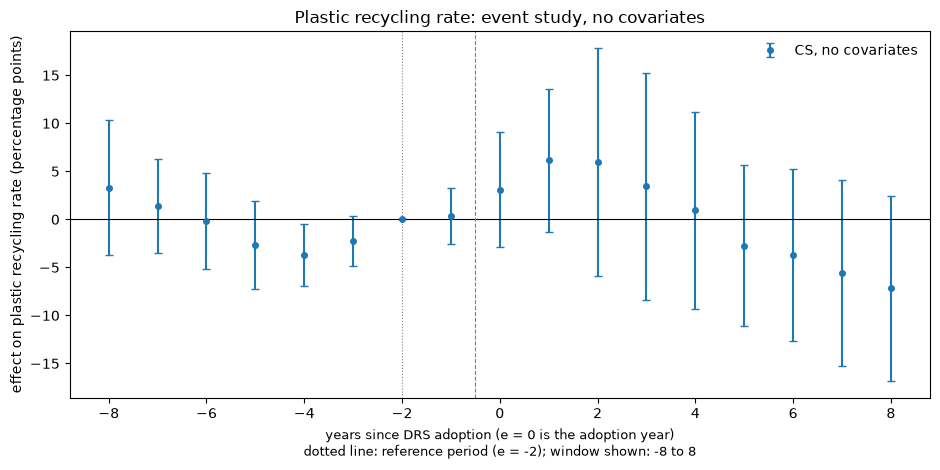

Event-time coefficients inside the plotted window:


,event_time,att,se,crit,ci_95
16,-8,3.28,3.58,1.96,"[-3.75, 10.30]"
17,-7,1.40,2.52,1.96,"[-3.54, 6.33]"
18,-6,-0.20,2.55,1.96,"[-5.19, 4.80]"
19,-5,-2.66,2.36,1.96,"[-7.29, 1.96]"
20,-4,-3.68,1.65,1.96,"[-6.93, -0.44]"
21,-3,-2.23,1.33,1.96,"[-4.83, 0.38]"
22,-2,0.00,NaN,1.96,"[nan, nan]"
23,-1,0.34,1.49,1.96,"[-2.59, 3.26]"
24,0,3.10,3.04,1.96,"[-2.86, 9.05]"
25,1,6.13,3.81,1.96,"[-1.33, 13.60]"


In [11]:
fig = plot_event_study({"CS, no covariates": r0}, window=(-8, 8), title="Plastic recycling rate: event study, no covariates", fname="event_study_nocov.png")
plt.show()

es = r0["dynamic"]
print("Event-time coefficients inside the plotted window:")
display(es[(es.event_time >= -8) & (es.event_time <= 8)].assign(ci_95=lambda t: [ci(a, s, c) for a, s, c in zip(t.att, t.se, t.crit)]).round(2))

In [12]:
# Plausibility checks from the plan: if something looks absurd, go back to the data before going further
es = r0["dynamic"]
pre = es[(es.event_time <= -2) & (es.event_time >= -6) & es.se.notna()]
post = es[(es.event_time >= 0) & (es.event_time <= 6) & es.se.notna()]
print(f"pre-period coefficients (e from -6 to -2): n={len(pre)}, mean |att|={pre.att.abs().mean():.2f}, "
      f"largest |att|={pre.att.abs().max():.2f}, CI excludes 0 in {(pre.att.abs() > pre.crit * pre.se).sum()} of {len(pre)}")
print(f"post-period coefficients (e from 0 to 6): n={len(post)}, mean att={post.att.mean():.2f}")

warn = []
if abs(r0["simple"][0]) > 20: warn.append("overall effect larger than 20 points")
if r0["simple"][1] > 10: warn.append("overall standard error above 10 points")
if r0["attgt"]["att"].abs().max() > 40: warn.append("some group-time effect above 40 points")
print("\nWARNINGS:" if warn else "\nNo automatic warning triggered.", *warn, sep="\n  - ")

big_cohorts = g_tab[g_tab.att.abs() > 15]
if len(big_cohorts):
    print("\nCohort-level effects larger than 15 points (check the data and the comparison group for these cohorts before interpreting):")
    display(big_cohorts[["cohort", "countries", "att", "se"]].round(2))

pre-period coefficients (e from -6 to -2): n=4, mean |att|=2.19, largest |att|=3.68, CI excludes 0 in 1 of 4
post-period coefficients (e from 0 to 6): n=7, mean att=1.87

No automatic warning triggered.

Cohort-level effects larger than 15 points (check the data and the comparison group for these cohorts before interpreting):


,cohort,countries,att,se
1,2003,DE,-19.76,3.28


### Reading the output (limits to keep in mind)

- **Few treated cohorts.** Many cohorts contain a single country (and 2022 has three). A group-time effect for a single-country cohort is effectively that country's change relative to the controls.
- **Short post-periods** for the recent adopters (2022–2024): Latvia, Malta, Slovakia, Romania and Ireland have 1–3 post-years, and Ireland's and Romania's 2023–2024 values are provisional in Eurostat.
- **Unbalanced data.** Countries enter the data at different years, so the set of comparison countries changes over time (see the table at the end of step 4). The earliest cohorts (Denmark 2002, Germany 2003) are compared with only a handful of countries in 2000–2003, and `csdid` treats unbalanced data as repeated cross-sections. Treat their estimates with extra caution.
- **Very long event-time windows** (e.g. +20 years) rest only on the earliest adopters (Denmark, Germany); the plot shows a limited window, which affects only what is displayed.
- **2020 reporting break.** Many countries drop in 2020 in the Eurostat series. Year effects absorb a common shift, but a country-specific change is not removed (robustness: step 8).
- **Treatment timing.** Latvia's DRS started in February 2022 (partial first year); `treatment_timing = "first_full_year"` in `SPEC` is the alternative (step 8).
- **Disputed start years** (Netherlands, Malta, Romania, Portugal) are listed in step 3. Portugal is coded as a control.
- **Estimand.** The outcome is *all* plastic packaging; the DRS covers drink containers only, so the signal is diluted.

## TWFE reference regression

Two-way fixed effects on the **same sample**, with one treatment dummy (`D = 1` from the adoption year on). This is shown only to compare with Callaway–Sant'Anna: with staggered adoption, TWFE can mix "already-treated" countries into the comparison group and give a misleading average, which is the reason for using CS.

In [13]:
tw = d.copy()
tw["D"] = ((tw.g > 0) & (tw.year >= tw.g)).astype(int)
tw_fit = smf.ols(f"{Y} ~ D + C(geo) + C(year)", data=tw).fit(cov_type="cluster", cov_kwds={"groups": pd.factorize(tw.geo)[0]})
b, se = float(tw_fit.params["D"]), float(tw_fit.bse["D"])
print(f"TWFE: effect of DRS = {b:.2f} (se {se:.2f}, clustered by country)  95% CI {ci(b, se)} | n = {int(tw_fit.nobs)}, countries = {tw.geo.nunique()}")

TWFE: effect of DRS = 3.81 (se 4.04, clustered by country)  95% CI [-4.12, 11.73] | n = 566, countries = 25


## Step 7 — Callaway–Sant'Anna with covariates, and comparison

Exactly the same estimation as step 6; only `xformla` changes (`~ log_gdp0 + epr0`). If the effect and the pre-trends change little, that is a sign of robustness. This runs only once `covariates.csv` is complete (step 5).

In [14]:
results = {"CS, no covariates": r0}
if RUN_COV:
    r1 = run_cs(d, covariates=SPEC["covariates"], label="CS, with covariates")
    results["CS, with covariates"] = r1
    print("Specification:", r1["xformla"])
    print(f"\nOverall ATT (simple):  {r1['simple'][0]:6.2f}  (se {r1['simple'][1]:.2f})  95% CI {ci(*r1['simple'])}")
    print(f"Overall ATT (event-study average, e >= 0): {r1['dynamic_overall'][0]:6.2f}  (se {r1['dynamic_overall'][1]:.2f})")
    plot_event_study(results, window=(-8, 8), title="Event study: with and without covariates", fname="event_study_cov_vs_nocov.png")
    plt.show()
else:
    print("Skipped: covariates not available yet (see step 5).")

rows = []
for lab, r in results.items():
    rows.append([lab, r["simple"][0], r["simple"][1], r["dynamic_overall"][0], r["dynamic_overall"][1]])
rows.append(["TWFE (reference)", b, se, np.nan, np.nan])
comp = pd.DataFrame(rows, columns=["estimate", "ATT simple", "se", "ATT event-study avg", "se (es)"]).round(2)
print("\nComparison:")
display(comp)

Skipped: covariates not available yet (see step 5).

Comparison:


,estimate,ATT simple,se,ATT event-study avg,se (es)
0,"CS, no covariates",-2.70,5.55,-5.57,4.85
1,TWFE (reference),3.81,4.04,NaN,NaN


In [15]:
# Save the tables
r0["attgt"].to_csv(OUT_DIR / "cs_nocov_attgt.csv", index=False)
r0["dynamic"].to_csv(OUT_DIR / "cs_nocov_event_study.csv", index=False)
r0["group"].to_csv(OUT_DIR / "cs_nocov_by_cohort.csv", index=False)
cohorts.to_csv(OUT_DIR / "cohort_table.csv")
log.to_csv(OUT_DIR / "sample_filter_log.csv", index=False)
comp.to_csv(OUT_DIR / "comparison_table.csv", index=False)
if RUN_COV:
    results["CS, with covariates"]["dynamic"].to_csv(OUT_DIR / "cs_cov_event_study.csv", index=False)
print("Saved to", OUT_DIR.resolve())

Saved to /Users/leannericard/mgt499_project/data/did_output


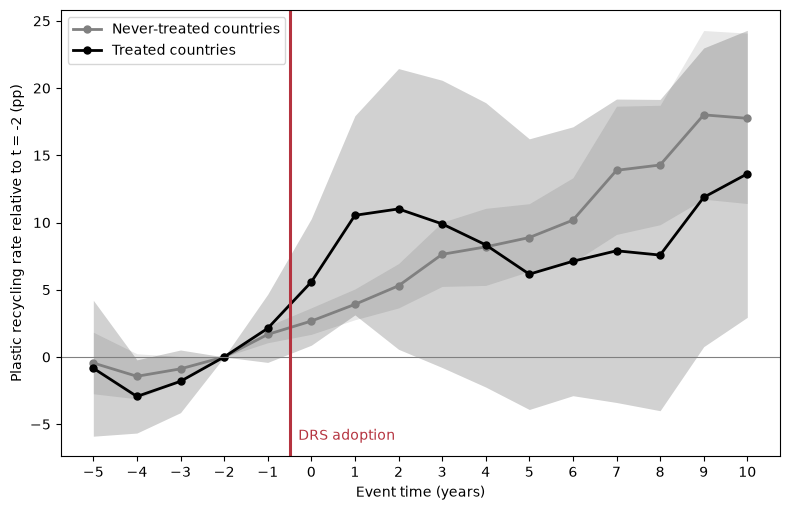

Countries per event time (treated / never-treated):


event,-5,-4,-3,-2,-1,0,1,2,3,4,5,6,7,8,9,10
Never-treated countries,15,15,15,15,15,15,15,15,15,15,15,15,15,15,15,15
Treated countries,8,8,9,10,10,10,8,8,5,5,5,5,5,5,4,4


In [16]:
# ---- Event-study plot: treated vs never-treated countries, relative to a reference year ----
REF = -1 - SPEC["anticipation"]    # reference event time: -2 (same as the CS estimate). Use REF = -1 to copy the paper figure.
WINDOW = (-5, 10)                  # event times displayed
MIN_UNITS = 2                      # hide event times with fewer countries than this

piv = d.pivot(index="geo", columns="year", values=Y)          # countries x years
g_of = d.groupby("geo").g.first()
treated = g_of[g_of > 0]
never = list(g_of[g_of == 0].index)

def path(geo, g):
    # outcome relative to the reference year, indexed by event time (year - g); None if the reference year is missing
    ref_year = g + REF
    if ref_year not in piv.columns or pd.isna(piv.loc[geo, ref_year]):
        return None
    s = (piv.loc[geo] - piv.loc[geo, ref_year]).dropna()
    s.index = s.index - g
    return s

rows = []
for geo, g in treated.items():                                 # treated: each country, at its own adoption year
    s = path(geo, g)
    if s is not None:
        rows += [("Treated countries", geo, e, v) for e, v in s.items()]
for g in sorted(treated.unique()):                             # never treated: borrow each cohort's adoption year
    for geo in never:
        s = path(geo, g)
        if s is not None:
            rows += [("Never-treated countries", geo, e, v) for e, v in s.items()]
ev = pd.DataFrame(rows, columns=["group", "geo", "event", "y"])

def summarize(x):
    # mean by event time, with standard errors clustered by country (a control country appears once per cohort)
    out = []
    for e, z in x.groupby("event"):
        m = z.y.mean()
        n = len(z)
        se = np.sqrt((z.assign(r=z.y - m).groupby("geo").r.sum() ** 2).sum()) / n if z.geo.nunique() > 1 else np.nan
        out.append((e, m, se, z.geo.nunique()))
    return pd.DataFrame(out, columns=["event", "mean", "se", "n_countries"])

res = {grp: summarize(x) for grp, x in ev.groupby("group")}
style = {"Never-treated countries": ("grey", "o"), "Treated countries": ("black", "o")}

fig, ax = plt.subplots(figsize=(8, 5.2))
for grp, (col, mk) in style.items():
    t = res[grp]
    t = t[(t.event >= WINDOW[0]) & (t.event <= WINDOW[1]) & (t.n_countries >= MIN_UNITS)].sort_values("event")
    ax.plot(t.event, t["mean"], color=col, marker=mk, lw=2, ms=5, label=grp)
    ax.fill_between(t.event, t["mean"] - 1.96 * t.se, t["mean"] + 1.96 * t.se, color=col, alpha=0.18, lw=0)
ax.axhline(0, color="grey", lw=0.8)
ax.axvline(-0.5, color="#b5333f", lw=2.2)
ax.text(-0.3, ax.get_ylim()[0] + 0.03 * (ax.get_ylim()[1] - ax.get_ylim()[0]), "DRS adoption", color="#b5333f", va="bottom")
ax.set_xlabel("Event time (years)")
ax.set_ylabel(f"Plastic recycling rate relative to t = {REF} (pp)")
ax.set_xticks(range(WINDOW[0], WINDOW[1] + 1))
ax.legend(frameon=True, loc="upper left")
fig.tight_layout()
fig.savefig(OUT_DIR / "event_study_treated_vs_never.png", dpi=200)
plt.show()

print("Countries per event time (treated / never-treated):")
display(pd.concat({g: res[g].set_index("event").n_countries for g in res}, axis=1).loc[WINDOW[0]:WINDOW[1]].T)

## Next (not done yet, as agreed)

- **Step 8 — robustness:** `treatment_timing = "first_full_year"`; `drop_break_flagged` and `drop_provisional`; `anticipation = 0`; `control_group = "nevertreated"`; leave-one-cohort-out; alternative Netherlands/Finland/Sweden dates. The options are already in `SPEC`; changing them triggers the warning in step 1, which is intended.
- **Step 9 — figures, table and limits for the report.**